# Integracion completa: Camara + Clasificacion + StockFish + Brazo Robotico

Este cuadernillo une el flujo actual del proyecto y agrega la capa puente del brazo robotico sin modificar el codigo de Arduino.

Por seguridad, el brazo inicia en modo simulacion con `ACTIVAR_BRAZO = False`. Cuando el flujo este validado, cambia a `True` y conecta el Arduino.

## 1. Instalacion opcional

In [15]:
# Ejecuta solo si falta alguna libreria:
# !pip install opencv-contrib-python numpy matplotlib torch torchvision python-chess pillow


## 2. Imports, rutas y configuracion

Las IPs de DroidCam pueden cambiar. Ajusta `DROIDCAM_DEVICE_IP` y `DROIDCAM_WIFI_IP` si DroidCam muestra otros valores.

In [16]:
from pathlib import Path
import json
import time
import subprocess
import urllib.request

import cv2
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import clear_output, display, SVG

import torch
import torch.nn as nn
from torchvision import transforms

import chess
import chess.engine
import chess.svg


def encontrar_root(start=None):
    start = Path.cwd() if start is None else Path(start)
    for p in [start, *start.parents]:
        if (p / "Dataset").exists() and (p / "Modelo de Clasificacion").exists():
            return p
    return Path.cwd()

ROOT = encontrar_root()

DATASET_DIR = ROOT / "Dataset"
ENTRENAMIENTO_DIR = DATASET_DIR / "Cilindros_Ajedrez"
CAMERA_OUTPUT_DIR = DATASET_DIR / "integracion_proyecto_completo_cilindros"
CAMERA_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_OUTPUT_DIR = ROOT / "Modelo de Clasificacion" / "outputs_cilindros"
MODEL_PATH = MODEL_OUTPUT_DIR / "modelo_cilindros_ajedrez.pth"
CLASS_NAMES_PATH = MODEL_OUTPUT_DIR / "class_names_cilindros.json"

STOCKFISH_CANDIDATES = [
    ROOT / "StockFish" / "stockfish-windows-x86-64-avx2.exe",
    ROOT / "StockFish" / "stockfish" / "stockfish-windows-x86-64-avx2.exe",
]

# DroidCam: deja varias opciones para que el notebook encuentre la que este activa.
DROIDCAM_DEVICE_IP = "10.59.45.246"
DROIDCAM_WIFI_IP = "10.204.120.246"
DROIDCAM_PORT = 4747

CAMERA_SOURCE = f"http://{DROIDCAM_DEVICE_IP}:{DROIDCAM_PORT}/video"
DROIDCAM_URLS = [
    f"http://{DROIDCAM_DEVICE_IP}:{DROIDCAM_PORT}/video",
    f"http://{DROIDCAM_DEVICE_IP}:{DROIDCAM_PORT}/mjpegfeed",
    f"http://{DROIDCAM_DEVICE_IP}:{DROIDCAM_PORT}/video?640x480",
    f"http://{DROIDCAM_DEVICE_IP}:{DROIDCAM_PORT}/",
    f"http://{DROIDCAM_WIFI_IP}:{DROIDCAM_PORT}/video",
    f"http://{DROIDCAM_WIFI_IP}:{DROIDCAM_PORT}/mjpegfeed",
    f"http://{DROIDCAM_WIFI_IP}:{DROIDCAM_PORT}/video?640x480",
    f"http://{DROIDCAM_WIFI_IP}:{DROIDCAM_PORT}/",
]

CAMERA_BACKENDS = [
    (cv2.CAP_DSHOW, "CAP_DSHOW"),
    (cv2.CAP_MSMF, "CAP_MSMF"),
    (cv2.CAP_ANY, "CAP_ANY"),
]
CAMERA_BACKEND_ACTUAL = None
CAMERA_WIDTH = 1280
CAMERA_HEIGHT = 720

ARUCO_DICT = cv2.aruco.DICT_4X4_50
BOARD_SIZE = 800
CELL_MARGIN = 0.00

STOCKFISH_TIME_LIMIT = 0.5
BLACK_TO_MOVE = chess.BLACK

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("ROOT:", ROOT)
print("Modelo cilindros:", MODEL_PATH)
print("Class names:", CLASS_NAMES_PATH)
print("StockFish candidatos:", STOCKFISH_CANDIDATES)
print("DroidCam fuente inicial:", CAMERA_SOURCE)
print("Device:", device)


ROOT: c:\Users\User\Desktop\Brazo Robotico
Modelo cilindros: c:\Users\User\Desktop\Brazo Robotico\Modelo de Clasificacion\outputs_cilindros\modelo_cilindros_ajedrez.pth
Class names: c:\Users\User\Desktop\Brazo Robotico\Modelo de Clasificacion\outputs_cilindros\class_names_cilindros.json
StockFish candidatos: [WindowsPath('c:/Users/User/Desktop/Brazo Robotico/StockFish/stockfish-windows-x86-64-avx2.exe'), WindowsPath('c:/Users/User/Desktop/Brazo Robotico/StockFish/stockfish/stockfish-windows-x86-64-avx2.exe')]
DroidCam fuente inicial: http://10.59.45.246:4747/video
Device: cuda


## 3. Utilidades de camara DroidCam

- Para IP directa: cierra DroidCam Client en Windows y deja abierta la app del celular.
- Para webcam virtual: deja DroidCam Client abierto y prueba indices locales.

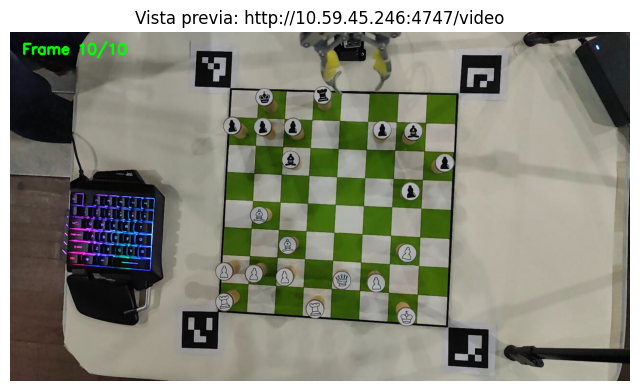

In [17]:
def mostrar_frame_notebook(frame_bgr, titulo="Frame", figsize=(8, 5)):
    frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)
    plt.figure(figsize=figsize)
    plt.imshow(frame_rgb)
    plt.title(titulo)
    plt.axis("off")
    plt.show()


def abrir_video_capture(source, backend=None):
    if isinstance(source, int):
        if backend is None:
            backend = CAMERA_BACKEND_ACTUAL if CAMERA_BACKEND_ACTUAL is not None else cv2.CAP_DSHOW
        cap = cv2.VideoCapture(source, backend)
        cap.set(cv2.CAP_PROP_FRAME_WIDTH, CAMERA_WIDTH)
        cap.set(cv2.CAP_PROP_FRAME_HEIGHT, CAMERA_HEIGHT)
    else:
        cap = cv2.VideoCapture(str(source))
    return cap


def abrir_camara(source=CAMERA_SOURCE):
    backend = CAMERA_BACKEND_ACTUAL if isinstance(source, int) else None
    cap = abrir_video_capture(source, backend=backend)
    if not cap.isOpened():
        raise RuntimeError(f"No se pudo abrir la fuente de camara: {source}")
    return cap


def leer_primer_frame(source, intentos=30, espera=0.08, backend=None):
    cap = abrir_video_capture(source, backend=backend)
    try:
        for _ in range(intentos):
            ok, frame = cap.read()
            if ok and frame is not None:
                return True, frame
            time.sleep(espera)
    finally:
        cap.release()
    return False, None


def probar_http_basico(urls=DROIDCAM_URLS, timeout=2):
    resultados = []
    for url in urls:
        try:
            with urllib.request.urlopen(url, timeout=timeout) as resp:
                content_type = resp.headers.get("Content-Type", "")
                status = getattr(resp, "status", "OK")
                print(f"HTTP OK {status}: {url} | {content_type}")
                resultados.append((url, True, content_type))
        except Exception as exc:
            print(f"HTTP fallo: {url} | {type(exc).__name__}: {exc}")
            resultados.append((url, False, str(exc)))
    return resultados


def probar_urls_droidcam(urls=DROIDCAM_URLS, mostrar=True):
    disponibles = []
    for url in urls:
        print("Probando:", url)
        ok, frame = leer_primer_frame(url, intentos=45, espera=0.1)
        if ok:
            disponibles.append(url)
            print("  OK", frame.shape)
            if mostrar:
                mostrar_frame_notebook(frame, titulo=url)
        else:
            print("  Sin video")
    return disponibles


def probar_indices_camara(max_index=20, mostrar=True):
    disponibles = []
    for backend, backend_name in CAMERA_BACKENDS:
        print(f"=== Backend {backend_name} ===")
        for idx in range(max_index + 1):
            ok, frame = leer_primer_frame(idx, intentos=12, espera=0.06, backend=backend)
            if ok:
                item = {"index": idx, "backend": backend, "backend_name": backend_name, "shape": frame.shape}
                disponibles.append(item)
                print(f"Indice {idx} con {backend_name}: OK {frame.shape}")
                if mostrar:
                    mostrar_frame_notebook(frame, titulo=f"Indice {idx} - {backend_name}")
            else:
                print(f"Indice {idx} con {backend_name}: sin video")
    return disponibles


def usar_fuente_ip(url):
    global CAMERA_SOURCE, CAMERA_BACKEND_ACTUAL
    CAMERA_SOURCE = url
    CAMERA_BACKEND_ACTUAL = None
    print("CAMERA_SOURCE =", CAMERA_SOURCE)


def usar_fuente_local(item):
    global CAMERA_SOURCE, CAMERA_BACKEND_ACTUAL
    CAMERA_SOURCE = int(item["index"])
    CAMERA_BACKEND_ACTUAL = item["backend"]
    print("CAMERA_SOURCE =", CAMERA_SOURCE)
    print("CAMERA_BACKEND_ACTUAL =", item["backend_name"])


def vista_previa_notebook(source=None, frames=15, intervalo=0.15):
    if source is None:
        source = CAMERA_SOURCE
    cap = abrir_camara(source)
    ultimo = None
    try:
        for i in range(frames):
            ok, frame = cap.read()
            if ok and frame is not None:
                ultimo = frame.copy()
                frame_marcado = frame.copy()
                cv2.putText(frame_marcado, f"Frame {i+1}/{frames}", (25, 45), cv2.FONT_HERSHEY_SIMPLEX, 1.0, (0, 255, 0), 3)
                clear_output(wait=True)
                mostrar_frame_notebook(frame_marcado, titulo=f"Vista previa: {source}")
            time.sleep(intervalo)
    finally:
        cap.release()
    return ultimo

# Prueba recomendada:
urls_ok = probar_urls_droidcam()
if urls_ok: usar_fuente_ip(urls_ok[0])
frame_preview = vista_previa_notebook(frames=10)


## 4. ArUco, enderezado y segmentacion

In [18]:
def ordenar_puntos(pts):
    pts = np.array(pts, dtype="float32")
    suma = pts.sum(axis=1)
    resta = np.diff(pts, axis=1)
    ordenados = np.zeros((4, 2), dtype="float32")
    ordenados[0] = pts[np.argmin(suma)]
    ordenados[2] = pts[np.argmax(suma)]
    ordenados[1] = pts[np.argmin(resta)]
    ordenados[3] = pts[np.argmax(resta)]
    return ordenados


def detectar_aruco(imagen_bgr):
    gray = cv2.cvtColor(imagen_bgr, cv2.COLOR_BGR2GRAY)
    aruco_dict = cv2.aruco.getPredefinedDictionary(ARUCO_DICT)
    params = cv2.aruco.DetectorParameters()
    if hasattr(cv2.aruco, "ArucoDetector"):
        detector = cv2.aruco.ArucoDetector(aruco_dict, params)
        corners, ids, _ = detector.detectMarkers(gray)
    else:
        corners, ids, _ = cv2.aruco.detectMarkers(gray, aruco_dict, parameters=params)
    return corners, ids


def obtener_esquinas_tablero_desde_aruco(corners, ids):
    if ids is None or len(ids) < 4:
        total = 0 if ids is None else len(ids)
        raise ValueError(f"Se necesitan 4 ArUco visibles. Detectados: {total}")

    datos = []
    for marker_corners, marker_id in zip(corners, ids.flatten()):
        pts = marker_corners.reshape(4, 2)
        datos.append({"id": int(marker_id), "corners": pts, "centro": pts.mean(axis=0)})

    datos = sorted(datos, key=lambda d: d["centro"][1])[:4]
    arriba = sorted(datos[:2], key=lambda d: d["centro"][0])
    abajo = sorted(datos[2:], key=lambda d: d["centro"][0])

    marker_tl = arriba[0]
    marker_tr = arriba[1]
    marker_bl = abajo[0]
    marker_br = abajo[1]

    board_tl = marker_tl["corners"][2]
    board_tr = marker_tr["corners"][3]
    board_br = marker_br["corners"][0]
    board_bl = marker_bl["corners"][1]

    return ordenar_puntos(np.array([board_tl, board_tr, board_br, board_bl], dtype="float32"))


def enderezar_tablero(imagen_bgr, corners, size=BOARD_SIZE):
    corners = ordenar_puntos(corners)
    destino = np.array([[0, 0], [size - 1, 0], [size - 1, size - 1], [0, size - 1]], dtype="float32")
    matriz = cv2.getPerspectiveTransform(corners, destino)
    return cv2.warpPerspective(imagen_bgr, matriz, (size, size))


def detectar_y_enderezar_tablero(imagen_bgr):
    corners, ids = detectar_aruco(imagen_bgr)
    corners_tablero = obtener_esquinas_tablero_desde_aruco(corners, ids)
    tablero_recto = enderezar_tablero(imagen_bgr, corners_tablero)
    debug = imagen_bgr.copy()
    cv2.aruco.drawDetectedMarkers(debug, corners, ids)
    cv2.polylines(debug, [corners_tablero.astype(int)], True, (0, 255, 0), 4)
    return tablero_recto, debug, corners_tablero, ids


def nombre_casilla_ajedrez(fila, col):
    columnas = ["a", "b", "c", "d", "e", "f", "g", "h"]
    filas = ["8", "7", "6", "5", "4", "3", "2", "1"]
    return columnas[col] + filas[fila]


def segmentar_casillas(tablero_bgr, n=8, margin=CELL_MARGIN):
    h, w = tablero_bgr.shape[:2]
    cell_h = h // n
    cell_w = w // n
    mx = int(cell_w * margin)
    my = int(cell_h * margin)
    casillas = []
    for fila in range(n):
        for col in range(n):
            y1, y2 = fila * cell_h, (fila + 1) * cell_h
            x1, x2 = col * cell_w, (col + 1) * cell_w
            crop = tablero_bgr[y1 + my:y2 - my, x1 + mx:x2 - mx]
            casillas.append({"casilla": nombre_casilla_ajedrez(fila, col), "fila": fila, "columna": col, "imagen": crop})
    return casillas


def mostrar_casillas(casillas):
    fig, axes = plt.subplots(8, 8, figsize=(12, 12))
    for item in casillas:
        fila, col = item["fila"], item["columna"]
        axes[fila, col].imshow(cv2.cvtColor(item["imagen"], cv2.COLOR_BGR2RGB))
        axes[fila, col].set_title(item["casilla"], fontsize=8)
        axes[fila, col].axis("off")
    plt.tight_layout()
    plt.show()


## 5. Captura automatica del tablero

In [19]:
def capturar_tablero(source=None, max_frames=160, mostrar_cada=10):
    if source is None:
        source = CAMERA_SOURCE
    cap = abrir_camara(source)
    tablero_capturado = None
    frame_capturado = None
    debug_capturado = None
    ultimo_frame = None
    ultimo_error = "Aun no se procesa ningun frame."

    print(f"Buscando tablero con 4 ArUco en fuente: {source}")
    try:
        for frame_idx in range(1, max_frames + 1):
            ok, frame = cap.read()
            if not ok or frame is None:
                ultimo_error = "No se pudo leer frame de la camara."
                time.sleep(0.05)
                continue

            ultimo_frame = frame.copy()
            try:
                tablero_actual, debug_actual, corners_tablero, ids = detectar_y_enderezar_tablero(frame)
                tablero_capturado = tablero_actual.copy()
                frame_capturado = frame.copy()
                debug_capturado = debug_actual.copy()
                print(f"Tablero detectado en frame {frame_idx}. ArUco detectados: {len(ids)}")
                break
            except Exception as exc:
                ultimo_error = str(exc)

            if mostrar_cada and frame_idx % mostrar_cada == 0:
                frame_marcado = frame.copy()
                cv2.putText(frame_marcado, ultimo_error[:80], (25, 45), cv2.FONT_HERSHEY_SIMPLEX, 0.75, (0, 0, 255), 2)
                clear_output(wait=True)
                print(f"Frame {frame_idx}/{max_frames}. {ultimo_error}")
                mostrar_frame_notebook(frame_marcado, titulo="Buscando ArUco")
            time.sleep(0.03)
    finally:
        cap.release()

    if tablero_capturado is None:
        print("No se detecto el tablero.")
        if ultimo_frame is not None:
            mostrar_frame_notebook(ultimo_frame, titulo="Ultimo frame capturado")
        return None, None, None

    timestamp = time.strftime("%Y%m%d_%H%M%S")
    cv2.imwrite(str(CAMERA_OUTPUT_DIR / f"captura_original_{timestamp}.jpg"), frame_capturado)
    cv2.imwrite(str(CAMERA_OUTPUT_DIR / f"captura_debug_aruco_{timestamp}.jpg"), debug_capturado)
    cv2.imwrite(str(CAMERA_OUTPUT_DIR / f"tablero_enderezado_{timestamp}.jpg"), tablero_capturado)

    mostrar_frame_notebook(debug_capturado, titulo="Deteccion ArUco")
    mostrar_frame_notebook(tablero_capturado, titulo="Tablero enderezado", figsize=(6, 6))
    return frame_capturado, tablero_capturado, timestamp


## 6. Modelo de clasificacion actualizado

In [20]:
class SEBlock(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        hidden = max(channels // reduction, 16)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(channels, hidden, 1),
            nn.SiLU(inplace=True),
            nn.Conv2d(hidden, channels, 1),
            nn.Sigmoid(),
        )

    def forward(self, x):
        return x * self.fc(self.pool(x))


class ResidualSEBlock(nn.Module):
    def __init__(self, in_ch, out_ch, stride=1, dropout=0.0):
        super().__init__()
        self.conv = nn.Sequential(
            nn.Conv2d(in_ch, out_ch, 3, stride=stride, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            nn.SiLU(inplace=True),
            nn.Conv2d(out_ch, out_ch, 3, padding=1, bias=False),
            nn.BatchNorm2d(out_ch),
            SEBlock(out_ch),
        )
        self.skip = nn.Identity()
        if stride != 1 or in_ch != out_ch:
            self.skip = nn.Sequential(
                nn.Conv2d(in_ch, out_ch, 1, stride=stride, bias=False),
                nn.BatchNorm2d(out_ch),
            )
        self.act = nn.SiLU(inplace=True)
        self.drop = nn.Dropout2d(dropout) if dropout > 0 else nn.Identity()

    def forward(self, x):
        out = self.conv(x) + self.skip(x)
        out = self.act(out)
        return self.drop(out)


class ChessCNN(nn.Module):
    """CNN residual con atencion SE para imagenes 100x100 de cilindros de ajedrez."""
    def __init__(self, num_classes):
        super().__init__()
        self.stem = nn.Sequential(
            nn.Conv2d(3, 64, 3, padding=1, bias=False),
            nn.BatchNorm2d(64),
            nn.SiLU(inplace=True),
        )
        self.features = nn.Sequential(
            ResidualSEBlock(64, 64, stride=1, dropout=0.02),
            ResidualSEBlock(64, 96, stride=2, dropout=0.03),
            ResidualSEBlock(96, 128, stride=1, dropout=0.03),
            ResidualSEBlock(128, 192, stride=2, dropout=0.04),
            ResidualSEBlock(192, 256, stride=1, dropout=0.04),
            ResidualSEBlock(256, 384, stride=2, dropout=0.05),
            ResidualSEBlock(384, 384, stride=1, dropout=0.05),
        )
        self.head = nn.Sequential(
            nn.AdaptiveAvgPool2d(1),
            nn.Flatten(),
            nn.LayerNorm(384),
            nn.Dropout(0.35),
            nn.Linear(384, 256),
            nn.SiLU(inplace=True),
            nn.Dropout(0.20),
            nn.Linear(256, num_classes),
        )

    def forward(self, x):
        x = self.stem(x)
        x = self.features(x)
        return self.head(x)




def recargar_modelo_clasificacion(path=MODEL_PATH):
    global model, class_names, num_classes, IMG_SIZE, predict_transform

    checkpoint = torch.load(path, map_location=device)
    if not isinstance(checkpoint, dict) or "model_state_dict" not in checkpoint:
        raise ValueError("El modelo guardado debe ser checkpoint con 'model_state_dict'.")

    class_names = checkpoint.get("class_names")
    if class_names is None and CLASS_NAMES_PATH.exists():
        with open(CLASS_NAMES_PATH, "r", encoding="utf-8") as f:
            class_names = json.load(f)
    if class_names is None:
        raise ValueError("No se encontraron class_names.")

    IMG_SIZE = int(checkpoint.get("img_size", 100))
    architecture = checkpoint.get("architecture", "desconocida")
    num_classes = len(class_names)

    model = ChessCNN(num_classes=num_classes).to(device)
    try:
        model.load_state_dict(checkpoint["model_state_dict"])
    except RuntimeError as exc:
        raise RuntimeError(
            "El checkpoint no coincide con la arquitectura de integracion. "
            "Este cuadernillo espera el modelo de outputs_cilindros entrenado como "
            "ChessCNN_ResidualSE_100x100_Cilindros."
        ) from exc
    model.eval()

    predict_transform = transforms.Compose([
        transforms.Resize((IMG_SIZE, IMG_SIZE)),
        transforms.ToTensor(),
        transforms.Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225]),
    ])

    print("Modelo cargado:", path)
    print("Arquitectura:", architecture)
    print("IMG_SIZE:", IMG_SIZE)
    print("Clases:", class_names)
    return model, class_names


LABEL_TO_PIECE = {
    "vacio": None,
    "peon_blanco": "P", "caballo_blanco": "N", "alfil_blanco": "B", "torre_blanco": "R", "reina_blanco": "Q", "rey_blanco": "K",
    "peon_negro": "p", "caballo_negro": "n", "alfil_negro": "b", "torre_negro": "r", "reina_negro": "q", "rey_negro": "k",
}


def predecir_casilla_bgr(img_bgr, modelo=None, nombres_clases=None):
    if "model" not in globals() or "predict_transform" not in globals():
        recargar_modelo_clasificacion(MODEL_PATH)

    modelo = model if modelo is None else modelo
    nombres_clases = class_names if nombres_clases is None else nombres_clases

    img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
    pil_img = Image.fromarray(img_rgb)
    x = predict_transform(pil_img).unsqueeze(0).to(device)

    modelo.eval()
    with torch.no_grad():
        logits = modelo(x)
        probs = torch.softmax(logits, dim=1)[0].cpu().numpy()
        pred_idx = int(np.argmax(probs))
    return nombres_clases[pred_idx], float(probs[pred_idx])


def clasificar_casillas(casillas):
    predicciones = {}
    for item in casillas:
        label, confidence = predecir_casilla_bgr(item["imagen"])
        predicciones[item["casilla"]] = {"label": label, "confidence": confidence, "fila": item["fila"], "columna": item["columna"]}
    return predicciones

model, class_names = recargar_modelo_clasificacion(MODEL_PATH)


Modelo cargado: c:\Users\User\Desktop\Brazo Robotico\Modelo de Clasificacion\outputs_cilindros\modelo_cilindros_ajedrez.pth
Arquitectura: ChessCNN_ResidualSE_100x100_Cilindros
IMG_SIZE: 100
Clases: ['alfil_blanco', 'alfil_negro', 'caballo_blanco', 'caballo_negro', 'peon_blanco', 'peon_negro', 'reina_blanco', 'reina_negro', 'rey_blanco', 'rey_negro', 'torre_blanco', 'torre_negro', 'vacio']


## 7. Convertir clasificacion a matriz y tablero chess

In [21]:
def predicciones_a_matriz_y_board(predicciones, turn=BLACK_TO_MOVE):
    matriz = []
    board = chess.Board(None)

    for fila in range(8):
        fila_vals = []
        for col in range(8):
            sq = nombre_casilla_ajedrez(fila, col)
            label = predicciones[sq]["label"]
            symbol = LABEL_TO_PIECE.get(label)
            fila_vals.append(symbol if symbol is not None else ".")
            if symbol is not None:
                board.set_piece_at(chess.parse_square(sq), chess.Piece.from_symbol(symbol))
        matriz.append(fila_vals)

    board.turn = turn
    board.castling_rights = 0
    board.ep_square = None
    return matriz, board


def mostrar_matriz(matriz):
    print("   a b c d e f g h")
    for i, fila in enumerate(matriz):
        print(8 - i, " ", " ".join(fila))


def mostrar_board(board, move=None):
    if move is not None:
        fill = {move.from_square: "#ced264", move.to_square: "#ced264"}
        display(SVG(chess.svg.board(board=board, fill=fill, size=420)))
    else:
        display(SVG(chess.svg.board(board=board, size=420)))
    print("FEN:", board.fen())
    status = board.status()
    if status != chess.STATUS_VALID:
        print("Advertencia python-chess status:", status)


## 8. StockFish

In [22]:
class StockfishUCI:
    def __init__(self, path, timeout=10):
        self.path = str(path)
        self.timeout = timeout
        self.proc = subprocess.Popen(
            [self.path],
            stdin=subprocess.PIPE,
            stdout=subprocess.PIPE,
            stderr=subprocess.STDOUT,
            text=True,
            bufsize=1,
            universal_newlines=True,
        )
        self._send("uci")
        self._read_until("uciok")
        self._send("isready")
        self._read_until("readyok")

    def _send(self, command):
        if self.proc.poll() is not None:
            raise RuntimeError("StockFish se cerro inesperadamente.")
        self.proc.stdin.write(command + "\n")
        self.proc.stdin.flush()

    def _read_until(self, token):
        lines = []
        start = time.time()
        while True:
            if time.time() - start > self.timeout:
                raise TimeoutError(f"StockFish no respondio con {token!r}.")
            line = self.proc.stdout.readline()
            if not line:
                continue
            line = line.strip()
            lines.append(line)
            if token in line:
                return lines

    def play(self, board, time_limit=0.5):
        self._send("position fen " + board.fen())
        self._send(f"go movetime {int(time_limit * 1000)}")
        lines = self._read_until("bestmove")
        bestmove_line = [line for line in lines if line.startswith("bestmove")][-1]
        parts = bestmove_line.split()
        if len(parts) < 2 or parts[1] == "(none)":
            return None
        return chess.Move.from_uci(parts[1])

    def quit(self):
        if self.proc.poll() is None:
            try:
                self._send("quit")
            except Exception:
                pass
            self.proc.terminate()


def encontrar_stockfish():
    for path in STOCKFISH_CANDIDATES:
        if Path(path).exists():
            return Path(path)
    raise FileNotFoundError("No se encontro StockFish. Revisa STOCKFISH_CANDIDATES.")


def abrir_stockfish():
    path = encontrar_stockfish()
    print("StockFish:", path)
    return StockfishUCI(path)


def pedir_jugada_negras(board, engine, time_limit=STOCKFISH_TIME_LIMIT):
    board_engine = board.copy(stack=False)
    board_engine.turn = chess.BLACK

    if board_engine.is_game_over():
        print("La partida ya termino segun python-chess.")
        return None, board_engine

    move = engine.play(board_engine, time_limit=time_limit)
    if move is None:
        print("StockFish no encontro jugada.")
        return None, board_engine

    san = board_engine.san(move)
    board_engine.push(move)
    print("Jugada de negras:", move.uci(), "SAN:", san)
    print("Movimiento fisico pendiente para el brazo:", move.uci())
    return move, board_engine


## 9. Configuracion del brazo robotico

Esta seccion usa el protocolo que ya existe en Arduino:

- `B<base>,S<hombro>,E<codo>` para mover una casilla calibrada.
- `191` para agarrar.
- `192` para soltar.
- `194` para cubeta.
- `195` y `196` para antichoque.
- `HOME` y `HOME1` para posiciones seguras.

In [23]:
try:
    import serial
except ImportError:
    serial = None

BRAZO_DIR = ROOT / "brazo_robotico"
PUNTOS_PATH = BRAZO_DIR / "puntos_negras.txt"

# Mantener False hasta probar todo en simulacion.
ACTIVAR_BRAZO = True
PUERTO_SERIE = "COM4"
BAUDIOS = 9600
SERIAL_TIMEOUT = 90

CORRECCION_CODO = 0.0
CORRECCION_HOMBRO = 1.5
CORRECCION_BASE = -6.8
COMANDO_CUBETA = 194

brazo_serial = None

print("Puntos brazo negras:", PUNTOS_PATH)
print("ACTIVAR_BRAZO:", ACTIVAR_BRAZO)

Puntos brazo negras: c:\Users\User\Desktop\Brazo Robotico\brazo_robotico\puntos_negras.txt
ACTIVAR_BRAZO: True


## 10. Capa puente Python -> Arduino

In [24]:
def conectar_brazo(puerto=PUERTO_SERIE, baudios=BAUDIOS):
    global brazo_serial
    if serial is None:
        raise ImportError("Falta pyserial. Instala con: pip install pyserial")
    if brazo_serial is not None and brazo_serial.is_open:
        print("Brazo ya conectado.")
        return brazo_serial
    brazo_serial = serial.Serial(puerto, baudios, timeout=1)
    time.sleep(2)
    print(f"Brazo conectado en {puerto} a {baudios} baudios")
    return brazo_serial


def cerrar_brazo():
    global brazo_serial
    if brazo_serial is not None and brazo_serial.is_open:
        brazo_serial.close()
        print("Conexion serial del brazo cerrada.")


def cargar_puntos(path=PUNTOS_PATH):
    puntos = {}
    path = Path(path)
    if not path.exists():
        raise FileNotFoundError(f"No existe el archivo de puntos para piezas negras: {path}")
    with open(path, "r", encoding="utf-8") as f:
        for linea in f:
            linea = linea.strip()
            if not linea or linea.startswith("#") or ":" not in linea:
                continue
            casilla, valores_txt = linea.split(":", 1)
            valores = [v.strip() for v in valores_txt.split(",")]
            if len(valores) == 3:
                puntos[casilla.strip().upper()] = [float(v) for v in valores]
    return puntos


def validar_puntos_completos(puntos=None):
    puntos = cargar_puntos() if puntos is None else puntos
    faltantes = []
    for file in "ABCDEFGH":
        for rank in "12345678":
            sq = file + rank
            if sq not in puntos:
                faltantes.append(sq)
    if faltantes:
        raise ValueError("Faltan casillas calibradas en puntos_negras.txt: " + ", ".join(faltantes))
    print(f"Puntos cargados correctamente: {len(puntos)} entradas")
    return puntos


def enviar_brazo(valor, activar=ACTIVAR_BRAZO, timeout=SERIAL_TIMEOUT):
    if not activar:
        print(f"[SIM BRAZO] {valor}")
        return "simulado"

    if brazo_serial is None or not brazo_serial.is_open:
        conectar_brazo()

    brazo_serial.write((str(valor) + "\n").encode())
    print("  Enviado:", valor)
    start = time.time()
    ultimas = []
    while True:
        if time.time() - start > timeout:
            raise TimeoutError(f"Arduino no respondio 'done' para {valor}. Ultimas respuestas: {ultimas[-5:]}")
        if brazo_serial.in_waiting:
            respuesta = brazo_serial.readline().decode(errors="replace").strip()
            if respuesta:
                ultimas.append(respuesta)
                print("  Arduino:", respuesta)
                if respuesta == "done":
                    return respuesta
        time.sleep(0.02)


def obtener_punto(casilla):
    casilla = str(casilla).upper()
    puntos = cargar_puntos()
    if casilla not in puntos:
        raise ValueError(f"Casilla '{casilla}' no esta calibrada en puntos_negras.txt")
    return puntos[casilla]


def mover_a_casilla(casilla, activar=ACTIVAR_BRAZO):
    base, elbow, hombro = obtener_punto(casilla)
    base_corregido = base + CORRECCION_BASE
    hombro_corregido = hombro + CORRECCION_HOMBRO
    elbow_corregido = elbow + CORRECCION_CODO
    enviar_brazo(f"B{base_corregido},S{hombro_corregido},E{elbow_corregido}", activar=activar)
    return True


def ir_home_libre(activar=ACTIVAR_BRAZO):
    print("  -> HOME libre")
    enviar_brazo("HOME", activar=activar)


def ir_home_carga(activar=ACTIVAR_BRAZO):
    print("  -> HOME carga")
    enviar_brazo("HOME1", activar=activar)


def enviar_antichoque(casilla, activar=ACTIVAR_BRAZO):
    fila = int(str(casilla)[1])
    enviar_brazo(195 if fila <= 4 else 196, activar=activar)


def mover_pieza(origen, destino, activar=ACTIVAR_BRAZO):
    origen = str(origen).upper()
    destino = str(destino).upper()
    print(f"\n=== BRAZO: {origen} -> {destino} ===")

    print("[1] Abrir pinza")
    enviar_brazo(192, activar=activar)

    print(f"[2] Ir a origen {origen}")
    mover_a_casilla(origen, activar=activar)

    print("[3] Agarrar pieza")
    enviar_brazo(191, activar=activar)

    print("[4] Antichoque origen")
    enviar_antichoque(origen, activar=activar)

    print("[5] HOME carga")
    ir_home_carga(activar=activar)

    if destino in {"194", "CUBETA", "CAPTURA"}:
        print("[6] Llevar pieza a cubeta")
        enviar_brazo(COMANDO_CUBETA, activar=activar)
    else:
        print(f"[6] Ir a destino {destino}")
        mover_a_casilla(destino, activar=activar)

        print("[7] Soltar pieza")
        enviar_brazo(192, activar=activar)

        print("[8] Antichoque destino")
        enviar_antichoque(destino, activar=activar)

    print("[9] HOME libre")
    ir_home_libre(activar=activar)
    print("=== BRAZO: movimiento completado ===")

## 11. Jugadas especiales: capturas y enroque

In [25]:
def casilla_desde_square(square):
    return chess.square_name(square).upper()


def obtener_movimientos_enroque(move, board):
    destino_rey = casilla_desde_square(move.to_square)
    if destino_rey == "G1":
        return [("E1", "G1"), ("H1", "F1")]
    if destino_rey == "C1":
        return [("E1", "C1"), ("A1", "D1")]
    if destino_rey == "G8":
        return [("E8", "G8"), ("H8", "F8")]
    if destino_rey == "C8":
        return [("E8", "C8"), ("A8", "D8")]
    raise ValueError(f"No se pudo interpretar el enroque: {move.uci()}")


def ejecutar_enroque_brazo(move, board_antes, activar=ACTIVAR_BRAZO):
    movimientos = obtener_movimientos_enroque(move, board_antes)
    print("Enroque detectado. Secuencia fisica:", movimientos)
    for origen, destino in movimientos:
        mover_pieza(origen, destino, activar=activar)
    board_despues = board_antes.copy(stack=False)
    board_despues.push(move)
    return board_despues


def ejecutar_jugada_brazo(move, board_antes, activar=ACTIVAR_BRAZO):
    if isinstance(move, str):
        move = chess.Move.from_uci(move)

    if move.promotion is not None:
        raise NotImplementedError("La coronacion esta omitida en esta version del proyecto.")

    if move not in board_antes.legal_moves:
        raise ValueError(f"La jugada {move.uci()} no es legal en el tablero antes de mover el brazo.")

    if board_antes.is_en_passant(move):
        raise NotImplementedError("La captura al paso esta omitida en esta version del proyecto.")

    if board_antes.is_castling(move):
        return ejecutar_enroque_brazo(move, board_antes, activar=activar)

    origen = casilla_desde_square(move.from_square)
    destino = casilla_desde_square(move.to_square)

    if board_antes.is_capture(move):
        print(f"Captura detectada en {destino}. Primero se retira la pieza capturada a la cubeta.")
        mover_pieza(destino, "CUBETA", activar=activar)

    print(f"Moviendo pieza que come o avanza: {origen} -> {destino}")
    mover_pieza(origen, destino, activar=activar)

    board_despues = board_antes.copy(stack=False)
    board_despues.push(move)
    return board_despues


def probar_brazo_manual(origen="E2", destino="E4", activar=ACTIVAR_BRAZO):
    validar_puntos_completos()
    mover_pieza(origen, destino, activar=activar)


def probar_brazo_con_jugada_uci(fen, move_uci, activar=ACTIVAR_BRAZO):
    board = chess.Board(fen)
    move = chess.Move.from_uci(move_uci)
    mostrar_board(board)
    board_despues = ejecutar_jugada_brazo(move, board, activar=activar)
    mostrar_board(board_despues, move=move)
    return board_despues

## 12. Pipeline completo: captura -> clasificacion -> StockFish -> brazo

Probando: http://10.59.45.246:4747/video
  OK (720, 1280, 3)


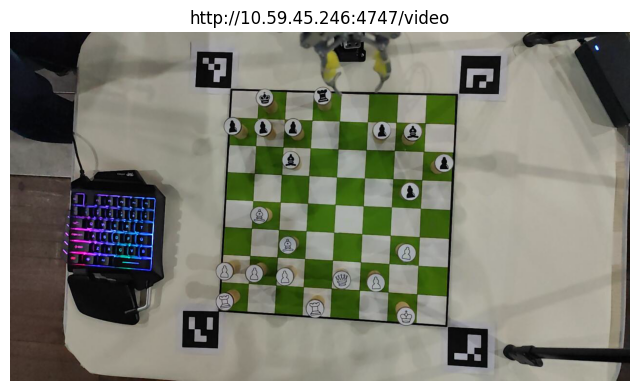

Probando: http://10.59.45.246:4747/mjpegfeed
  Sin video
Probando: http://10.59.45.246:4747/video?640x480
  OK (480, 640, 3)


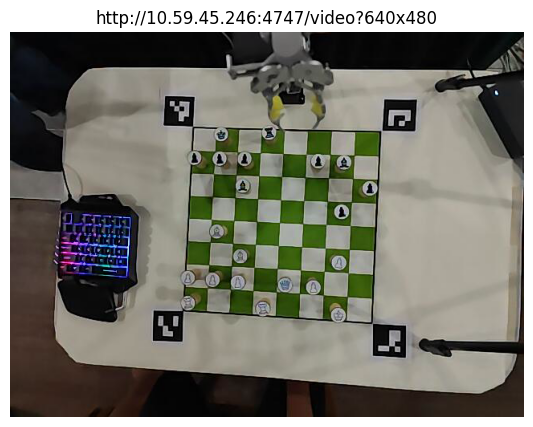

Probando: http://10.59.45.246:4747/
  Sin video
Probando: http://10.204.120.246:4747/video
  Sin video
Probando: http://10.204.120.246:4747/mjpegfeed


KeyboardInterrupt: 

In [26]:
def validar_board_para_stockfish(board):
    status = board.status()
    if status != chess.STATUS_VALID:
        raise ValueError(
            "La posicion detectada no es valida para StockFish. "
            "Corrige el FEN manualmente antes de continuar. Status: " + str(status)
        )
    return True


def ejecutar_turno_completo(source=None, engine=None, activar_brazo=ACTIVAR_BRAZO, mostrar_segmentos=False, confirmar_brazo=True):
    if source is None:
        source = CAMERA_SOURCE

    recargar_modelo_clasificacion(MODEL_PATH)
    validar_puntos_completos()

    frame, tablero_recto, timestamp = capturar_tablero(source)
    if tablero_recto is None:
        return None

    mostrar_frame_notebook(tablero_recto, titulo="Tablero enderezado", figsize=(6, 6))
    casillas = segmentar_casillas(tablero_recto)
    if mostrar_segmentos:
        mostrar_casillas(casillas)

    predicciones = clasificar_casillas(casillas)
    matriz, board_detectado = predicciones_a_matriz_y_board(predicciones, turn=chess.BLACK)

    mostrar_matriz(matriz)
    mostrar_board(board_detectado)

    fen_manual = input("Si necesitas corregir la posicion, pega FEN aqui. Enter para continuar: ").strip()
    if fen_manual:
        board_detectado = chess.Board(fen_manual)
        board_detectado.turn = chess.BLACK
        mostrar_board(board_detectado)

    validar_board_para_stockfish(board_detectado)

    engine_externo = engine is not None
    if engine is None:
        engine = abrir_stockfish()

    try:
        move, board_stockfish = pedir_jugada_negras(board_detectado, engine, time_limit=STOCKFISH_TIME_LIMIT)
    finally:
        if not engine_externo:
            engine.quit()

    if move is not None:
        mostrar_board(board_stockfish, move=move)
        ejecutar = activar_brazo
        if activar_brazo and confirmar_brazo:
            resp = input(f"Confirmar movimiento fisico del brazo para {move.uci()}? escribe SI: ").strip().upper()
            ejecutar = resp == "SI"
            if not ejecutar:
                print("Movimiento fisico cancelado. Se conserva la logica.")
        board_brazo = ejecutar_jugada_brazo(move, board_detectado, activar=ejecutar)
    else:
        board_brazo = None

    out_json = CAMERA_OUTPUT_DIR / f"predicciones_{timestamp}.json"
    out_matrix = CAMERA_OUTPUT_DIR / f"matriz_{timestamp}.json"
    with open(out_json, "w", encoding="utf-8") as f:
        json.dump(predicciones, f, ensure_ascii=False, indent=2)
    with open(out_matrix, "w", encoding="utf-8") as f:
        json.dump({
            "matriz": matriz,
            "fen_detectado": board_detectado.fen(),
            "move_stockfish": move.uci() if move else None,
            "fen_stockfish": board_stockfish.fen() if move else None,
            "fen_brazo": board_brazo.fen() if board_brazo is not None else None,
            "brazo_activado": bool(activar_brazo),
        }, f, ensure_ascii=False, indent=2)

    print("Predicciones guardadas:", out_json)
    print("Matriz guardada:", out_matrix)

    return {
        "frame": frame,
        "tablero_recto": tablero_recto,
        "casillas": casillas,
        "predicciones": predicciones,
        "matriz": matriz,
        "board_detectado": board_detectado,
        "move": move,
        "board_stockfish": board_stockfish if move else None,
        "board_brazo": board_brazo,
    }

# Uso recomendado:
urls_ok = probar_urls_droidcam()
if urls_ok: usar_fuente_ip(urls_ok[0])
resultado = ejecutar_turno_completo(CAMERA_SOURCE, activar_brazo=True, mostrar_segmentos=False)

## 13. Pruebas por etapas

In [ ]:
# 1) Verificar puntos calibrados de piezas negras sin mover hardware.
# puntos = validar_puntos_completos()

# 2) Simular un movimiento negro simple.
# probar_brazo_manual("E7", "E5", activar=False)

# 3) Simular una captura negra: retira primero la pieza blanca capturada a la cubeta.
# fen_captura = "4k3/8/8/8/4p3/3P4/8/4K3 b - - 0 1"
# probar_brazo_con_jugada_uci(fen_captura, "e4d3", activar=False)

# 4) Simular enroque negro corto.
# fen_enroque = "r3k2r/8/8/8/8/8/8/4K3 b kq - 0 1"
# probar_brazo_con_jugada_uci(fen_enroque, "e8g8", activar=False)

# 5) Probar camara + StockFish + brazo simulado.
# urls_ok = probar_urls_droidcam()
# if urls_ok: usar_fuente_ip(urls_ok[0])
# resultado = ejecutar_turno_completo(CAMERA_SOURCE, activar_brazo=False)

# 6) Cuando todo este validado, activar hardware.
# ACTIVAR_BRAZO = True
# conectar_brazo("COM4")
# resultado = ejecutar_turno_completo(CAMERA_SOURCE, activar_brazo=True)
# cerrar_brazo()


Cargando modelo de clasificacion...
Modelo cargado: c:\Users\User\Desktop\Brazo Robotico\Modelo de Clasificacion\outputs_cilindros\modelo_cilindros_ajedrez.pth
Arquitectura: ChessCNN_ResidualSE_100x100_Cilindros
IMG_SIZE: 100
Clases: ['alfil_blanco', 'alfil_negro', 'caballo_blanco', 'caballo_negro', 'peon_blanco', 'peon_negro', 'reina_blanco', 'reina_negro', 'rey_blanco', 'rey_negro', 'torre_blanco', 'torre_negro', 'vacio']
Inicializando brazo robotico...
Puntos cargados correctamente: 64 entradas
Brazo ya conectado.
Arduino conectado. Enviando HOME para estabilizar el brazo antes de iniciar la partida.
  Enviado: HOME
  Arduino: done
Brazo listo para iniciar la partida.
Abriendo StockFish...
StockFish: c:\Users\User\Desktop\Brazo Robotico\StockFish\stockfish-windows-x86-64-avx2.exe
Turno 1: realiza tu jugada blanca.
Presiona ESPACIO para que el brazo juegue negras. Presiona ESC para terminar.
ESPACIO detectado. Ejecutando turno...

========== TURNO 1: StockFish / brazo juega negras ==

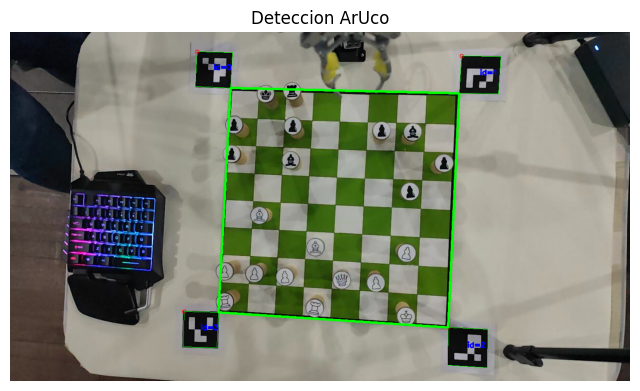

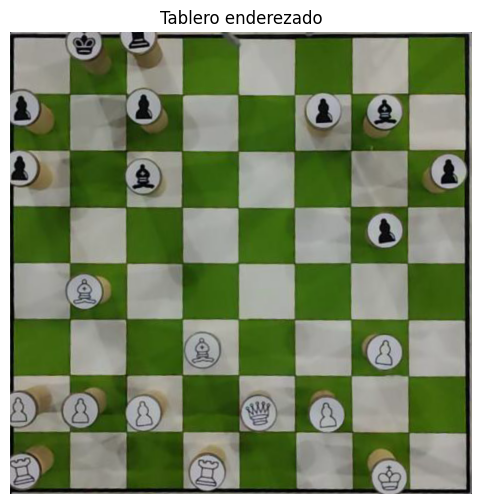

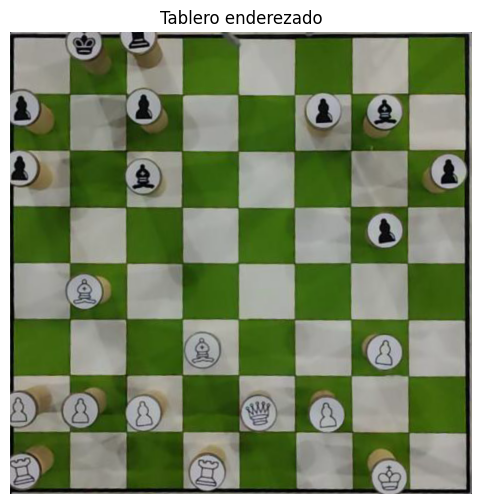

   a b c d e f g h
8   . k r . . . . .
7   p . p . . p b .
6   p . b . . . . p
5   . . . . . . p .
4   . B . . . . . .
3   . . . B . . P .
2   P P P . Q P . .
1   R . . R . . K .


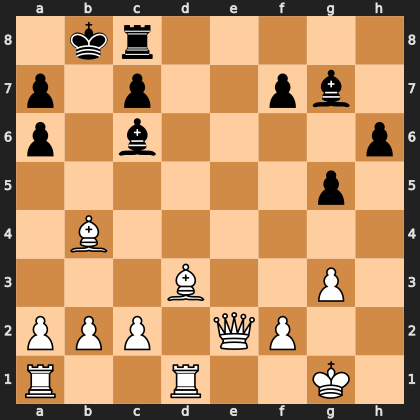

FEN: 1kr5/p1p2pb1/p1b4p/6p1/1B6/3B2P1/PPP1QP2/R2R2K1 b - - 0 1
Jugada de negras: h6h5 SAN: h5
Movimiento fisico pendiente para el brazo: h6h5


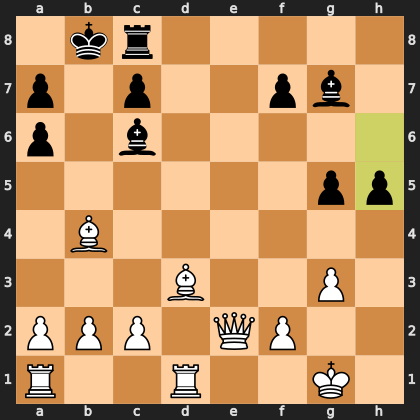

FEN: 1kr5/p1p2pb1/p1b5/6pp/1B6/3B2P1/PPP1QP2/R2R2K1 w - - 0 2
Moviendo pieza que come o avanza: H6 -> H5

=== BRAZO: H6 -> H5 ===
[1] Abrir pinza
  Enviado: 192
  Arduino: done
[2] Ir a origen H6
  Enviado: B140.39999999999998,S72.5,E62.0
  Arduino: done
[3] Agarrar pieza
  Enviado: 191
  Arduino: done
[4] Antichoque origen
  Enviado: 196
  Arduino: done
[5] HOME carga
  -> HOME carga
  Enviado: HOME1
  Arduino: done
[6] Ir a destino H5
  Enviado: B135.2,S65.0,E70.8
  Arduino: done
[7] Soltar pieza
  Enviado: 192
  Arduino: done
[8] Antichoque destino
  Enviado: 196
  Arduino: done
[9] HOME libre
  -> HOME libre
  Enviado: HOME
  Arduino: done
=== BRAZO: movimiento completado ===
Turno completado. Predicciones guardadas: c:\Users\User\Desktop\Brazo Robotico\Dataset\integracion_proyecto_completo_cilindros\partida_predicciones_20260612_155107.json
Matriz guardada: c:\Users\User\Desktop\Brazo Robotico\Dataset\integracion_proyecto_completo_cilindros\partida_matriz_20260612_155107.json
Turn

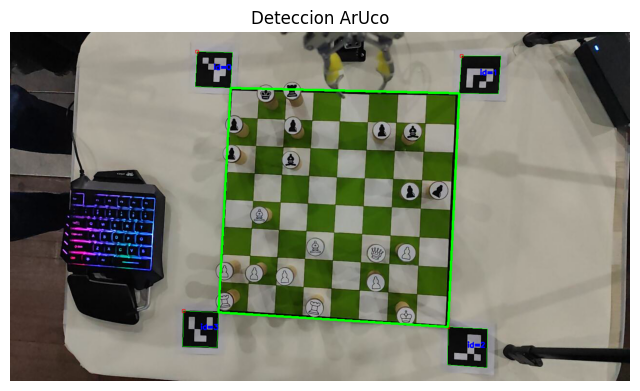

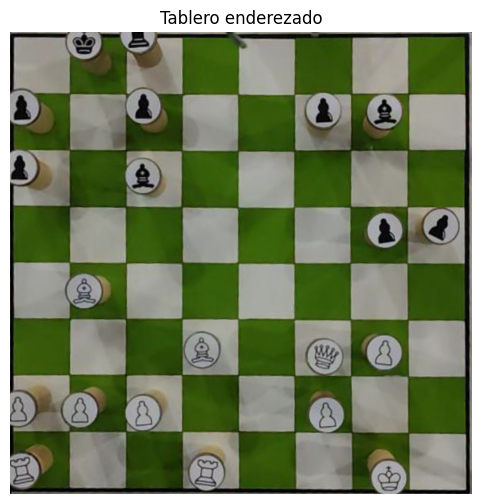

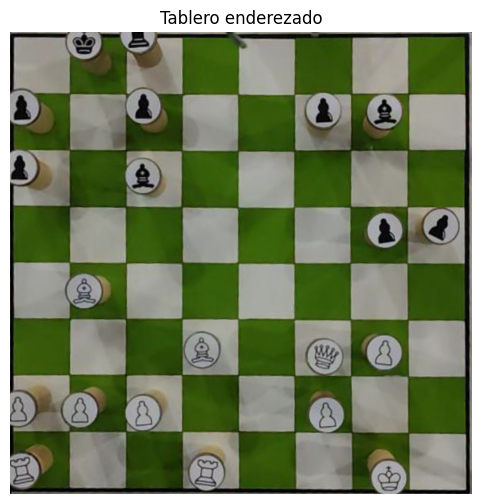

   a b c d e f g h
8   . k r . . . . .
7   p . p . . p b .
6   p . b . . . . .
5   . . . . . . p p
4   . B . . . . . .
3   . . . B . Q P .
2   P P P . . P . .
1   R . . R . . K .


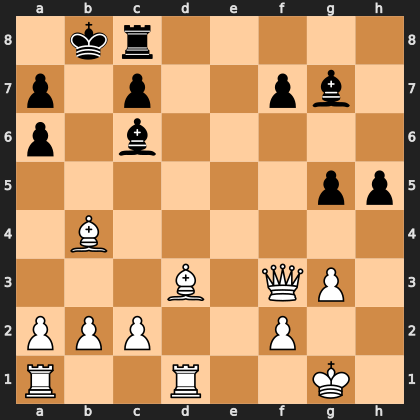

FEN: 1kr5/p1p2pb1/p1b5/6pp/1B6/3B1QP1/PPP2P2/R2R2K1 b - - 0 1
Jugada de negras: c6f3 SAN: Bxf3
Movimiento fisico pendiente para el brazo: c6f3


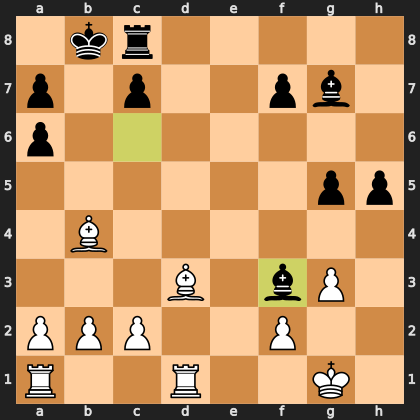

FEN: 1kr5/p1p2pb1/p7/6pp/1B6/3B1bP1/PPP2P2/R2R2K1 w - - 0 2
Captura detectada en F3. Primero se retira la pieza capturada a la cubeta.

=== BRAZO: F3 -> CUBETA ===
[1] Abrir pinza
  Enviado: 192
  Arduino: done
[2] Ir a origen F3
  Enviado: B114.9,S57.8,E86.8
  Arduino: done
[3] Agarrar pieza
  Enviado: 191
  Arduino: done
[4] Antichoque origen
  Enviado: 195
  Arduino: done
[5] HOME carga
  -> HOME carga
  Enviado: HOME1
  Arduino: done
[6] Llevar pieza a cubeta
  Enviado: 194
  Arduino: done
[9] HOME libre
  -> HOME libre
  Enviado: HOME
  Arduino: done
=== BRAZO: movimiento completado ===
Moviendo pieza que come o avanza: C6 -> F3

=== BRAZO: C6 -> F3 ===
[1] Abrir pinza
  Enviado: 192
  Arduino: done
[2] Ir a origen C6
  Enviado: B80.7,S82.0,E53.0
  Arduino: done
[3] Agarrar pieza
  Enviado: 191
  Arduino: done
[4] Antichoque origen
  Enviado: 196
  Arduino: done
[5] HOME carga
  -> HOME carga
  Enviado: HOME1
  Arduino: done
[6] Ir a destino F3
  Enviado: B114.9,S57.8,E86.8
  Ardu

In [28]:
# ============================================================
# CICLO FINAL DE PARTIDA: jugador humano vs brazo robotico
# ============================================================
# Flujo por turno:
# 1. El brazo se inicializa y va a HOME.
# 2. Tu haces tu jugada blanca fisicamente.
# 3. Presionas ESPACIO en el teclado KNUP.
# 4. El sistema captura el tablero, clasifica y StockFish calcula negras sin pedir confirmaciones.
# 5. El brazo ejecuta la jugada negra.
# 6. Repite hasta salir.


def esperar_espacio_o_salir(turno):
    """Espera una tecla real sin Enter: ESPACIO continua, ESC termina.

    Requiere la libreria keyboard. En Windows suele funcionar bien con Jupyter local.
    Si no esta instalada, ejecuta: %pip install keyboard
    """
    try:
        import keyboard
    except ImportError as exc:
        raise ImportError("Falta la libreria keyboard. Ejecuta en una celda: %pip install keyboard") from exc

    print(f"Turno {turno}: realiza tu jugada blanca.")
    print("Presiona ESPACIO para que el brazo juegue negras. Presiona ESC para terminar.")

    # Limpia estados previos para evitar que una tecla mantenida dispare dos turnos.
    while keyboard.is_pressed("space") or keyboard.is_pressed("esc"):
        time.sleep(0.05)

    while True:
        if keyboard.is_pressed("esc"):
            print("ESC detectado. Terminando ciclo de partida.")
            while keyboard.is_pressed("esc"):
                time.sleep(0.05)
            return False
        if keyboard.is_pressed("space"):
            print("ESPACIO detectado. Ejecutando turno...")
            while keyboard.is_pressed("space"):
                time.sleep(0.05)
            time.sleep(0.20)
            return True
        time.sleep(0.05)


def validar_board_para_stockfish_local(board):
    status = board.status()
    if status != chess.STATUS_VALID:
        print("La posicion detectada no es valida para StockFish. Status:", status)
        print("No se enviara esta posicion a StockFish ni al brazo. Corrige fisicamente el tablero/camara y presiona ESPACIO otra vez.")
        return False
    return True


def ejecutar_turno_partida(
    source=None,
    engine=None,
    activar_brazo=True,
    mostrar_segmentos=False,
):
    if source is None:
        source = CAMERA_SOURCE

    frame, tablero_recto, timestamp = capturar_tablero(source)
    if tablero_recto is None:
        return None

    mostrar_frame_notebook(tablero_recto, titulo="Tablero enderezado", figsize=(6, 6))
    casillas = segmentar_casillas(tablero_recto)
    if mostrar_segmentos:
        mostrar_casillas(casillas)

    predicciones = clasificar_casillas(casillas)
    matriz, board_detectado = predicciones_a_matriz_y_board(predicciones, turn=chess.BLACK)

    mostrar_matriz(matriz)
    mostrar_board(board_detectado)

    if not validar_board_para_stockfish_local(board_detectado):
        return None

    move, board_stockfish = pedir_jugada_negras(board_detectado, engine, time_limit=STOCKFISH_TIME_LIMIT)
    if move is None:
        print("StockFish no devolvio movimiento. Turno cancelado.")
        return None

    mostrar_board(board_stockfish, move=move)
    board_brazo = ejecutar_jugada_brazo(move, board_detectado, activar=activar_brazo)

    out_json = CAMERA_OUTPUT_DIR / f"partida_predicciones_{timestamp}.json"
    out_matrix = CAMERA_OUTPUT_DIR / f"partida_matriz_{timestamp}.json"
    with open(out_json, "w", encoding="utf-8") as f:
        json.dump(predicciones, f, ensure_ascii=False, indent=2)
    with open(out_matrix, "w", encoding="utf-8") as f:
        json.dump({
            "modo": "ciclo_partida",
            "matriz": matriz,
            "fen_detectado": board_detectado.fen(),
            "move_stockfish": move.uci(),
            "fen_stockfish": board_stockfish.fen(),
            "fen_brazo": board_brazo.fen(),
            "brazo_activado": bool(activar_brazo),
        }, f, ensure_ascii=False, indent=2)

    print("Turno completado. Predicciones guardadas:", out_json)
    print("Matriz guardada:", out_matrix)

    return {
        "frame": frame,
        "tablero_recto": tablero_recto,
        "casillas": casillas,
        "predicciones": predicciones,
        "matriz": matriz,
        "board_detectado": board_detectado,
        "move": move,
        "board_stockfish": board_stockfish,
        "board_brazo": board_brazo,
    }

def inicializar_brazo_partida(puerto=PUERTO_SERIE, activar_brazo=True):
    print("Inicializando brazo robotico...")
    validar_puntos_completos()

    if activar_brazo:
        conectar_brazo(puerto)
        print("Arduino conectado. Enviando HOME para estabilizar el brazo antes de iniciar la partida.")
        enviar_brazo("HOME", activar=True)
        time.sleep(1.0)
        print("Brazo listo para iniciar la partida.")
    else:
        print("Modo simulacion activo. No se movera el hardware.")
        enviar_brazo("HOME", activar=False)


def ciclo_partida_con_brazo(
    source=None,
    puerto=PUERTO_SERIE,
    activar_brazo=True,
    max_turnos=None,
    mostrar_segmentos=False,
):
    if source is None:
        source = CAMERA_SOURCE

    print("Cargando modelo de clasificacion...")
    recargar_modelo_clasificacion(MODEL_PATH)
    inicializar_brazo_partida(puerto=puerto, activar_brazo=activar_brazo)

    print("Abriendo StockFish...")
    engine = abrir_stockfish()
    resultados = []
    turno = 1

    try:
        while True:
            if max_turnos is not None and turno > max_turnos:
                print("Maximo de turnos alcanzado.")
                break

            continuar = esperar_espacio_o_salir(turno)
            if not continuar:
                print("Ciclo de partida terminado por el usuario.")
                break

            print(f"\n========== TURNO {turno}: StockFish / brazo juega negras ==========")
            try:
                resultado = ejecutar_turno_partida(
                    source=source,
                    engine=engine,
                    activar_brazo=activar_brazo,
                    mostrar_segmentos=mostrar_segmentos,
                )
                resultados.append(resultado)
                print(f"Turno {turno} finalizado. Realiza tu siguiente jugada blanca y vuelve a presionar espacio.")
                turno += 1
            except Exception as exc:
                print("Error durante el turno:", repr(exc))
                print("No se pedira confirmacion. Revisa tablero/camara si hace falta y presiona ESPACIO para intentar el siguiente turno, o ESC para salir.")
                continue
    finally:
        try:
            engine.quit()
        except Exception:
            pass
        print("StockFish cerrado.")

    return resultados


# ------------------------------------------------------------
# EJECUCION FINAL
# ------------------------------------------------------------
# Primero prueba en simulacion:
# Si falta keyboard, instala primero:
# %pip install keyboard
# resultados_partida = ciclo_partida_con_brazo(CAMERA_SOURCE, puerto="COM4", activar_brazo=False)

# Cuando ya estes listo para mover hardware, ejecuta esta linea:
resultados_partida = ciclo_partida_con_brazo(CAMERA_SOURCE, puerto="COM4", activar_brazo=True)